# Phase 4B — HistGradientBoosting development and fair comparison

Only the optional HistGradientBoostingClassifier (HGB) is trained in this notebook. Preserve all prior models, results and preprocessing. Use the existing 32,940 development records and identical five stratified folds; never parse or use the held-out 8,236 records. No resampling/class weighting, threshold optimization, native categorical mode, new split, nested CV or Phase 5A work.

## Colab instructions and sources

Upload this notebook with `preprocessing.py`, `02_cleaned_dataset.csv`, `03_split_indices.json`, `05_model_comparison_summary.md` and `05_model_comparison.ipynb`. Alternatively mount Drive and set PROJECT_DIR. Standard Colab dependencies (sklearn >=1.2, pandas, NumPy, Matplotlib, threadpoolctl) suffice. Raw CSV/project documents are optional runtime files for byte-integrity checks, not model inputs. Runtime may take minutes; threadpoolctl bounds OpenMP/BLAS to one thread, GridSearchCV uses n_jobs=1. Output is `05b_hist_gradient_boosting_summary.md`; save the executed notebook to retain embedded plots/tables. No fitted model, encoded CSV or new split is exported.

Reviewed README, project DOCX, cleaned dataset/saved split, approved preprocessing, Phase 2C/3 summaries and Phase 4 notebook/summary. Campaign-start availability of all predictors remains Provisional. Prior work is unchanged and previous model grids are not rerun.

## 1. Integrity, development-only loader and identical CV recipe

SHA-256 binds exact cleaned-file values and row ordering before applying saved indices. CSV loader skips held-out data rows and materializes only development data, in saved order. Hashing a whole file is an integrity check, not access to held-out features/labels for modeling. Verify full partition coverage and reproducibility, and compare the preserved Phase 4 notebook's deterministic saved-row ordering/fold recipe. No new train-test split.


In [1]:
from pathlib import Path
import sys,json,hashlib,warnings,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator,TransformerMixin,clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV,ParameterGrid
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,roc_curve,precision_recall_curve,confusion_matrix
from threadpoolctl import threadpool_limits
from IPython.display import display
PROJECT_DIR=Path.cwd()  # or mounted Drive project folder
required=['02_cleaned_dataset.csv','03_split_indices.json','preprocessing.py','05_model_comparison_summary.md','05_model_comparison.ipynb']
if any(not (PROJECT_DIR/n).is_file() for n in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Upload the required files into PROJECT_DIR') from exc
    files.upload()
if any(not (PROJECT_DIR/n).is_file() for n in required):raise FileNotFoundError(required)
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor,make_cv,FEATURES,CATEGORICAL,NUMERICAL,RECENCY

def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes={n:sha(PROJECT_DIR/n) for n in required}
for optional in ['dataset.csv','README.md','MSI5001 Project Bank Telemarketing .docx','03_preprocessing_summary.md','04_baseline_summary.md']:
    if (PROJECT_DIR/optional).is_file():input_hashes[optional]=sha(PROJECT_DIR/optional)
split=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
assert input_hashes['02_cleaned_dataset.csv']==split['input_sha256'] and split['row_count']==41176
idx=np.asarray(split['development_indices'],dtype=int);held=np.asarray(split['held_out_indices'],dtype=int)
assert len(idx)==32940 and len(held)==8236
assert len(np.unique(idx))==len(idx) and len(np.unique(held))==len(held) and not np.intersect1d(idx,held).size
np.testing.assert_array_equal(np.sort(np.r_[idx,held]),np.arange(41176))
keep=set(idx.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda n:n>0 and n-1 not in keep)
assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
dev.index=np.sort(idx);dev=dev.loc[idx].copy();snapshot=dev.copy(deep=True)
assert not dev.isna().any().any() and dev.y.isin([0,1]).all()
assert np.isfinite(dev[NUMERICAL+RECENCY].to_numpy()).all()
assert dev.recency_available.isin([0,1]).all()
assert dev.loc[dev.recency_available.eq(0),'recency_days'].eq(0).all()
assert dev.recency_days.between(0,27).all() and not dev.recency_days.eq(999).any()
X=dev[FEATURES].copy();y=dev.y.copy()
folds=list(make_cv().split(X,y))
for (a,b),(aa,bb) in zip(folds,make_cv().split(X,y)):
    np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
seen=np.zeros(len(X),int)
for a,b in folds:
    assert len(a)==26352 and len(b)==6588 and not np.intersect1d(a,b).size
    assert not set(X.iloc[a].index).intersection(held) and not set(X.iloc[b].index).intersection(held)
    seen[b]+=1
assert (seen==1).all()
# Verify the preserved Phase 4 notebook used the identical recipe, saved-row ordering and imported factory.
oldnb=json.loads((PROJECT_DIR/'05_model_comparison.ipynb').read_text())
oldcode='\n'.join(''.join(c['source']) for c in oldnb['cells'] if c['cell_type']=='code')
assert 'folds=list(make_cv().split(X,y))' in oldcode and 'dev=dev.loc[idx].copy()' in oldcode
assert "split['development_indices']" in oldcode and "input_hashes['02_cleaned_dataset.csv']==split['input_sha256']" in oldcode
TRAIN_KEYS={frozenset(X.iloc[a].index):i+1 for i,(a,b) in enumerate(folds)}
VAL_KEYS={frozenset(X.iloc[b].index):i+1 for i,(a,b) in enumerate(folds)}
DEV_KEY=frozenset(X.index)
fold_hash=hashlib.sha256(b''.join(idx[b].astype('<i8').tobytes() for _,b in folds)).hexdigest()
print('Same saved development ordering/CV recipe as Phase 4; fold validation-position hash:',fold_hash)
print('Development rows only:',X.shape,'positives:',int(y.sum()),'| held-out rows never parsed:',len(held))



Same saved development ordering/CV recipe as Phase 4; fold validation-position hash: 6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4
Development rows only: (32940, 15) positives: 3711 | held-out rows never parsed: 8236


## 2. Compatibility and fresh audited pipelines before model training

No change or new model name in preprocessing.py is needed. `make_preprocessor('decision_tree')` already returns the approved DT/RF unscaled numbers and full training-only one-hot configuration. HistGradientBoosting supports dense numeric data. `categorical_features=None` explicitly treats every dummy as its own numeric 0/1 predictor and disables native categorical inference. This is an optional extension beyond the three primary course models, justified by nonlinear interactions on structured binary-classification data, not assumed superiority.

Complete pipeline: approved preprocessing → stateless numeric representation guard → HGB. The guard checks every transformed training array before classifier.fit and returns values unchanged; it neither scales nor learns feature values. Validate finite numeric output, one-hot bits, availability and recency placeholders. Clone the complete pipeline before training; audit fitted categorical masks after each fit. Quantitative and recency values remain unscaled and 999 is forbidden. LR/ConditionalRecencyScaler are neither changed nor used here.

Baseline: learning_rate=0.1, max_iter=100, max_leaf_nodes=31, l2_regularization=0, early_stopping=False, random_state=42, class_weight=None. The same fixed probability >=0.5 rule as Phase 4 applies. ROC-AUC/AP use positive probabilities; zero_division=0 for precision/recall/F1. AP is Average Precision, not trapezoidal PR area.

Grid: learning_rate=[0.05,0.1], max_iter=[100,200], max_leaf_nodes=[15,31], l2_regularization=[0,1]. Learning rate shrinks each update; iteration count fixes total stages; leaf count regulates tree partition complexity; L2 shrinks leaf values. Fixed disabled early stopping avoids internal validation splits. Exactly 16 combinations and 80 candidate-fold fits, plus one final post-selection refit and five untuned fits = 86 fits. No adaptive expansion/reduction planned.


In [2]:
METRICS=['Accuracy','Precision','Recall','F1','ROC_AUC','AP']

def scores(actual,prob):
    pred=(prob>=.5).astype(int)
    return dict(Accuracy=accuracy_score(actual,pred),Precision=precision_score(actual,pred,zero_division=0),
        Recall=recall_score(actual,pred,zero_division=0),F1=f1_score(actual,pred,zero_division=0),
        ROC_AUC=roc_auc_score(actual,prob),AP=average_precision_score(actual,prob))

def signature(pre):
    ct=pre.named_steps['preprocessor']
    return {'categories':[a.tolist() for a in ct.named_transformers_['categorical'].categories_],
            'names':pre.get_feature_names_out().tolist()}

class FiniteNumericCheck(TransformerMixin,BaseEstimator):
    """Stateless representation guard after approved preprocessing, before HGB fit."""
    def _check(self,z):
        assert isinstance(z,np.ndarray) and z.ndim==2 and np.issubdtype(z.dtype,np.number)
        assert np.isfinite(z).all()
        assert np.isin(z[:,:-9],[0.,1.]).all(), 'One-hot block must be numeric indicators'
        assert np.isin(z[:,-1],[0.,1.]).all(), 'Availability must stay binary'
        assert (z[z[:,-1]==0,-2]==0).all(), 'Unavailable recency placeholder must remain zero'
        assert ((z[:,-2]>=0)&(z[:,-2]<=27)).all(), 'Original 999 sentinel forbidden'
        return z
    def fit(self,z,y=None):
        self._check(z);self.n_features_in_=z.shape[1];return self
    def transform(self,z):
        z=self._check(z)
        assert z.shape[1]==self.n_features_in_
        return z
    def get_feature_names_out(self,input_features=None):
        return np.asarray(input_features,dtype=object)

FIT_AUDIT=[];PRED_AUDIT=[];WARNINGS=[];PHASE='untuned';ALLOW_REFIT=False
class AuditedHGBPipeline(Pipeline):
    def fit(self,X,y=None,**params):
        key=frozenset(X.index)
        assert key in TRAIN_KEYS or (ALLOW_REFIT and key==DEV_KEY)
        pre=self.named_steps['preprocessing']
        assert not hasattr(pre.named_steps['preprocessor'],'transformers_')
        clf=self.named_steps['classifier']
        assert clf.categorical_features is None and clf.early_stopping is False and clf.class_weight is None and clf.random_state==42
        with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
            warnings.simplefilter('always')
            result=super().fit(X,y,**params)
        for w in caught:WARNINGS.append({'phase':PHASE,'category':w.category.__name__,'message':str(w.message)})
        ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical']
        for c,levels in zip(CATEGORICAL,enc.categories_):np.testing.assert_array_equal(levels,np.sort(X[c].unique()))
        assert enc.drop is None and enc.handle_unknown=='ignore'
        assert not hasattr(ct.named_transformers_['numerical'],'mean_')
        assert not hasattr(ct.named_transformers_['recency'],'mean_')
        assert clf.is_categorical_ is None or not np.any(clf.is_categorical_)
        assert clf.n_iter_==clf.max_iter and clf.do_early_stopping_ is False
        FIT_AUDIT.append({'phase':PHASE,'fold':TRAIN_KEYS.get(key,'post-search refit'),'rows':len(X),
                          'features':clf.n_features_in_,'iterations':clf.n_iter_,'warnings':len(caught),'status':'PASS'})
        return result
    def predict_proba(self,X,**params):
        key=frozenset(X.index);assert key in VAL_KEYS,'Only fixed development validation predictions allowed'
        pre=self.named_steps['preprocessing'];before=signature(pre)
        z=pre.transform(X)
        self.named_steps['finite_check'].transform(z)
        np.testing.assert_array_equal(z[:,-9:],X[NUMERICAL+RECENCY].to_numpy())
        with threadpool_limits(limits=1):out=super().predict_proba(X,**params)
        assert signature(pre)==before and np.isfinite(out).all() and ((out>=0)&(out<=1)).all()
        PRED_AUDIT.append({'phase':PHASE,'fold':VAL_KEYS[key],'rows':len(X),'status':'PASS'})
        return out

def factory():
    # Existing DT/RF factory is the same approved unscaled numerical configuration.
    return AuditedHGBPipeline([('preprocessing',make_preprocessor('decision_tree')),
        ('finite_check',FiniteNumericCheck()),
        ('classifier',HistGradientBoostingClassifier(learning_rate=.1,max_iter=100,max_leaf_nodes=31,
          l2_regularization=0.,early_stopping=False,random_state=42,class_weight=None,categorical_features=None))])
clone(factory())
assert not hasattr(factory().named_steps['preprocessing'].named_steps['preprocessor'],'transformers_')
GRID={'classifier__learning_rate':[.05,.1],'classifier__max_iter':[100,200],
      'classifier__max_leaf_nodes':[15,31],'classifier__l2_regularization':[0.,1.]}
assert len(ParameterGrid(GRID))==16
print('Cloneability verified before training; dense numeric representation guard precedes classifier.')
print('No additional preprocessing.py configuration needed; categorical_features=None, early_stopping=False.')

def scorer(est,data,actual):
    return scores(actual,est.predict_proba(data)[:,list(est.classes_).index(1)])



Cloneability verified before training; dense numeric representation guard precedes classifier.
No additional preprocessing.py configuration needed; categorical_features=None, early_stopping=False.


## 3. Untuned HGB baseline first

Each fold trains a new complete pipeline on 26,352 original development rows and predicts 6,588 validation rows. No global matrix or fitted vocabulary is reused. Every OOF slot receives one prediction from a model that excluded that row. Record fold scores, feature count, fixed iteration count, fit time and warnings. Audits assert vocabulary matches training rows and validation uses the same learned state with numeric/recency values unchanged.


In [3]:
start_all=time.perf_counter();started=time.perf_counter();untuned_rows=[];baseline_audit=[];oof=np.full(len(X),np.nan)
for fold,(tr,va) in enumerate(folds,start=1):
    estimator=factory();t=time.perf_counter();estimator.fit(X.iloc[tr],y.iloc[tr]);fit_seconds=time.perf_counter()-t
    p=estimator.predict_proba(X.iloc[va])[:,list(estimator.classes_).index(1)]
    oof[va]=p;untuned_rows.append({'model':'HistGradientBoosting','fold':fold,**scores(y.iloc[va],p)})
    baseline_audit.append({'fold':fold,'train_rows':len(tr),'validation_rows':len(va),'fit_seconds':fit_seconds,
                           'features':estimator.named_steps['classifier'].n_features_in_,'iterations':estimator.named_steps['classifier'].n_iter_,'status':'PASS'})
    print('Untuned HGB complete: fold',fold)
assert np.isfinite(oof).all()
untuned=pd.DataFrame(untuned_rows);untuned_seconds=time.perf_counter()-started
display(untuned);display(pd.DataFrame(baseline_audit))



Untuned HGB complete: fold 1
Untuned HGB complete: fold 2
Untuned HGB complete: fold 3
Untuned HGB complete: fold 4
Untuned HGB complete: fold 5


,model,fold,Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,HistGradientBoosting,1,0.899514,0.631579,0.258760,0.367113,0.801227,0.440846
1,HistGradientBoosting,2,0.898452,0.632727,0.234501,0.342183,0.786152,0.435501
2,HistGradientBoosting,3,0.899211,0.635417,0.246631,0.355340,0.787113,0.424695
3,HistGradientBoosting,4,0.898300,0.633333,0.230458,0.337945,0.795083,0.454304
4,HistGradientBoosting,5,0.898907,0.650980,0.223419,0.332665,0.780021,0.441713


,fold,train_rows,validation_rows,fit_seconds,features,iterations,status
0,1,26352,6588,0.927937,42,100,PASS
1,2,26352,6588,0.851739,42,100,PASS
2,3,26352,6588,0.873746,42,100,PASS
3,4,26352,6588,0.878857,42,100,PASS
4,5,26352,6588,0.839416,42,100,PASS


## 4. AP-selected GridSearchCV

Joint scoring returns six metrics from class-1 probabilities. `refit='AP'` uses the correctly named Average Precision scorer result, `n_jobs=1`, `error_score='raise'`, the exact common folds and complete cloned pipelines. All candidate AP/ROC means/sample SDs and timings are displayed. All metrics are computed for each candidate; selected five-fold metrics are reported in full.

Mean ± sample SD uses ddof=1 from the five split scores (not GridSearchCV's native ddof=0 std). The chosen configuration's split scores are tuning-reused **selection estimates**, potentially optimistic. The one full-development refit occurs after search, never before CV; no predictions/metrics/Top-K from that fitted object's training data are allowed. Early stopping remains off and iteration counts are audited across all 100/200-stage fits. No nested CV is run.


In [4]:
PHASE='grid search';ALLOW_REFIT=True;started=time.perf_counter()
search=GridSearchCV(factory(),GRID,scoring=scorer,refit='AP',cv=folds,n_jobs=1,error_score='raise',return_train_score=False)
search.fit(X,y)
search_seconds=time.perf_counter()-started;ALLOW_REFIT=False
r=search.cv_results_;candidate_rows=[];selected_rows=[]
for candidate,params in enumerate(r['params']):
    row={'parameters':json.dumps(params,sort_keys=True),'rank_AP':int(r['rank_test_AP'][candidate]),
         'mean_fit_seconds':r['mean_fit_time'][candidate],'mean_score_seconds':r['mean_score_time'][candidate]}
    for metric in METRICS:
        vals=np.asarray([r[f'split{i}_test_{metric}'][candidate] for i in range(5)])
        assert np.isfinite(vals).all();row[metric+'_mean']=vals.mean();row[metric+'_SD']=vals.std(ddof=1)
    candidate_rows.append(row)
for fold in range(5):selected_rows.append({'model':'HistGradientBoosting','fold':fold+1,
    **{metric:float(r[f'split{fold}_test_{metric}'][search.best_index_]) for metric in METRICS}})
selected=pd.DataFrame(selected_rows);candidates=pd.DataFrame(candidate_rows)
assert len(FIT_AUDIT)==86 and len(PRED_AUDIT)==85
assert sum(row['rows']==len(X) for row in FIT_AUDIT)==1
assert all(row['status']=='PASS' for row in FIT_AUDIT+PRED_AUDIT)
print('Grid complete:',search.best_params_,'AP:',search.best_score_,'seconds:',round(search_seconds,2))
display(selected);display(candidates[['parameters','rank_AP','AP_mean','AP_SD','ROC_AUC_mean','ROC_AUC_SD','mean_fit_seconds','mean_score_seconds']])



Grid complete: {'classifier__l2_regularization': 1.0, 'classifier__learning_rate': 0.05, 'classifier__max_iter': 200, 'classifier__max_leaf_nodes': 15} AP: 0.4480688918206422 seconds: 99.9


,model,fold,Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,HistGradientBoosting,1,0.899211,0.632653,0.250674,0.359073,0.810399,0.449426
1,HistGradientBoosting,2,0.897845,0.640816,0.211590,0.318136,0.791854,0.442427
2,HistGradientBoosting,3,0.899059,0.638989,0.238544,0.347399,0.788073,0.427352
3,HistGradientBoosting,4,0.900729,0.677419,0.226415,0.339394,0.803839,0.469064
4,HistGradientBoosting,5,0.899514,0.670886,0.213997,0.324490,0.780681,0.452076


,parameters,rank_AP,AP_mean,AP_SD,ROC_AUC_mean,ROC_AUC_SD,mean_fit_seconds,mean_score_seconds
0,"{""classifier__l2_regularization"": 0.0, ""classi...",5,0.446923,0.014697,0.794122,0.012523,0.789596,0.052239
1,"{""classifier__l2_regularization"": 0.0, ""classi...",8,0.446531,0.012252,0.795288,0.012299,1.011899,0.059440
2,"{""classifier__l2_regularization"": 0.0, ""classi...",7,0.446655,0.016581,0.793915,0.010589,1.426995,0.074689
3,"{""classifier__l2_regularization"": 0.0, ""classi...",13,0.442447,0.011931,0.792777,0.009787,1.567118,0.073790
4,"{""classifier__l2_regularization"": 0.0, ""classi...",6,0.446716,0.016051,0.794003,0.011032,0.720186,0.052472
5,"{""classifier__l2_regularization"": 0.0, ""classi...",14,0.439412,0.010735,0.789919,0.008285,0.839507,0.052769
6,"{""classifier__l2_regularization"": 0.0, ""classi...",12,0.442594,0.015280,0.792566,0.009397,1.340722,0.071460
7,"{""classifier__l2_regularization"": 0.0, ""classi...",16,0.433244,0.009231,0.785127,0.006288,1.487636,0.072479
8,"{""classifier__l2_regularization"": 1.0, ""classi...",4,0.447537,0.013504,0.795131,0.011893,0.790027,0.051589
9,"{""classifier__l2_regularization"": 1.0, ""classi...",3,0.447787,0.013058,0.795661,0.011904,0.992006,0.056457


## 5. Import prior results and compare like with like

Read the existing Phase 4 Markdown tables (no reruns/edits). Old fold scores were published to six decimals, so reconstructed means/SDs have rounding uncertainty around 1e-6. Show all four models at both untuned and selected-CV stages, with six metrics and computational cost. Prior timings are historical context, not a controlled hardware comparison. Do not claim statistical significance from selection-fold differences.

For untuned HGB only, pooled OOF and each validation fold are ranked at top 5%, 10%, 20%; K=ceil(fraction*N), ties use saved cleaned-row position without labels. Precision=captured/K, Recall=captured/all actual subscribers, Lift=Precision/prevalence. Import prior untuned LR/DT/RF pooled/fold-local results. Fold-local K rounding means pooled and per-fold selected counts can differ slightly.

Pooled ranks combine five probability scales and overlapping training sets; fold-local summaries help expose this limitation. Ties can influence coarse-tree rankings. No tuned HGB targeting is computed or presented as comparable to untuned targeting. Less-biased tuned targeting would require an approved nested design: five outer × (80 inner candidate-fold fits + one refit) = 405 additional HGB fits. Deferred, not executed.


In [5]:
previous_text=(PROJECT_DIR/'05_model_comparison_summary.md').read_text()

def table_after(heading):
    tail=previous_text.split(heading,1)[1];lines=[];started=False
    for line in tail.splitlines():
        if line.startswith('| '):lines.append(line);started=True
        elif started:break
    assert len(lines)>2,heading
    header=[c.strip() for c in lines[0].split('|')[1:-1]]
    data=[[c.strip() for c in line.split('|')[1:-1]] for line in lines[2:]]
    frame=pd.DataFrame(data,columns=header)
    for c in frame:
        if c not in ['model','stage','parameters','best_parameters']:
            try:frame[c]=pd.to_numeric(frame[c])
            except (ValueError,TypeError):pass
    return frame
old_untuned=table_after('## Untuned individual fold results')
old_tuned=table_after('## Tuned selected-configuration fold results')
old_business=table_after('## Untuned development OOF business targeting')
old_fold_business=table_after('For transparency, fold-local rank summaries')
old_cost=table_after('## Computational cost and audits')
assert len(old_untuned)==15 and len(old_tuned)==15 and len(old_business)==9
assert all(old_untuned.groupby('model').size()==5)
all_folds=pd.concat([old_untuned.assign(stage='untuned'),old_tuned.assign(stage='tuned selection CV'),
                     untuned.assign(stage='untuned'),selected.assign(stage='tuned selection CV')],ignore_index=True)
means=all_folds.groupby(['stage','model'])[METRICS].mean();sds=all_folds.groupby(['stage','model'])[METRICS].std(ddof=1)
comparison=pd.DataFrame(index=means.index)
for metric in METRICS:comparison[metric+' mean ± SD']=[f'{means.loc[i,metric]:.6f} ± {sds.loc[i,metric]:.6f}' for i in means.index]
display(comparison)
# Published old fold scores are rounded to 6 decimal places; retain that evidence limit.

def topk(actual,prob,fraction,ties):
    k=int(np.ceil(len(actual)*fraction));order=np.lexsort((np.asarray(ties),-np.asarray(prob)))
    captured=int(np.asarray(actual)[order[:k]].sum());total=int(np.asarray(actual).sum());precision=captured/k
    return dict(contacts=k,captured_subscribers=captured,Precision_at_K=precision,Recall_at_K=captured/total,Lift_at_K=precision/(total/len(actual)))
new_business=[];fold_business=[]
for fraction in [.05,.1,.2]:
    new_business.append({'model':'HistGradientBoosting','target_fraction':fraction,**topk(y,oof,fraction,X.index)})
    for fold,(_,va) in enumerate(folds,start=1):fold_business.append({'model':'HistGradientBoosting','fraction':fraction,'fold':fold,
        **topk(y.iloc[va],oof[va],fraction,X.iloc[va].index)})
new_business=pd.DataFrame(new_business);fold_business=pd.DataFrame(fold_business)
business_comparison=pd.concat([old_business,new_business],ignore_index=True)
fold_summary=fold_business.groupby(['model','fraction'])[['Precision_at_K','Recall_at_K','Lift_at_K']].agg(['mean','std']).reset_index()
fold_summary.columns=['model','fraction','Precision_mean','Precision_SD','Recall_mean','Recall_SD','Lift_mean','Lift_SD']
fold_comparison=pd.concat([old_fold_business,fold_summary],ignore_index=True)
display(business_comparison);display(fold_business);display(fold_comparison)
cost=pd.concat([old_cost,pd.DataFrame([
    {'model':'HistGradientBoosting','stage':'untuned CV','configurations':1,'CV_fits':5,'refits':0,'wall_seconds':untuned_seconds},
    {'model':'HistGradientBoosting','stage':'GridSearchCV','configurations':16,'CV_fits':80,'refits':1,'wall_seconds':search_seconds}])],ignore_index=True)
display(cost)



Accuracy mean ± SD  ...         AP mean ± SD
stage              model                                      ...                     
tuned selection CV DecisionTree          0.897086 ± 0.000759  ...  0.420499 ± 0.016574
                   HistGradientBoosting  0.899271 ± 0.001033  ...  0.448069 ± 0.015163
                   LogisticRegression    0.899180 ± 0.001207  ...  0.422430 ± 0.011606
                   RandomForest          0.899514 ± 0.000872  ...  0.445417 ± 0.016226
untuned            DecisionTree          0.832726 ± 0.004730  ...  0.180763 ± 0.008793
                   HistGradientBoosting  0.898877 ± 0.000508  ...  0.439412 ± 0.010735
                   LogisticRegression    0.899120 ± 0.001282  ...  0.422182 ± 0.011316
                   RandomForest          0.883394 ± 0.002188  ...  0.361307 ± 0.010714

[8 rows x 6 columns]

,model,target_fraction,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,LogisticRegression,0.05,1647,960,0.582878,0.258690,5.173808
1,LogisticRegression,0.10,3294,1562,0.474196,0.420911,4.209108
2,LogisticRegression,0.20,6588,2269,0.344414,0.611425,3.057127
3,DecisionTree,0.05,1647,255,0.154827,0.068715,1.374293
4,DecisionTree,0.10,3294,875,0.265634,0.235786,2.357855
5,DecisionTree,0.20,6588,1332,0.202186,0.358933,1.794665
6,RandomForest,0.05,1647,826,0.501518,0.222582,4.451630
7,RandomForest,0.10,3294,1397,0.424104,0.376448,3.764484
8,RandomForest,0.20,6588,2126,0.322708,0.572891,2.864457
9,HistGradientBoosting,0.05,1647,985,0.598057,0.265427,5.308542


,model,fraction,fold,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,HistGradientBoosting,0.05,1,330,203,0.615152,0.273585,5.461750
1,HistGradientBoosting,0.05,2,330,195,0.590909,0.262803,5.246508
2,HistGradientBoosting,0.05,3,330,197,0.596970,0.265499,5.300319
3,HistGradientBoosting,0.05,4,330,200,0.606061,0.269542,5.381034
4,HistGradientBoosting,0.05,5,330,196,0.593939,0.263795,5.266316
5,HistGradientBoosting,0.10,1,659,315,0.477997,0.424528,4.243995
6,HistGradientBoosting,0.10,2,659,327,0.496206,0.440701,4.405671
7,HistGradientBoosting,0.10,3,659,311,0.471927,0.419137,4.190103
8,HistGradientBoosting,0.10,4,659,332,0.503794,0.447439,4.473036
9,HistGradientBoosting,0.10,5,659,318,0.482549,0.427995,4.278647


,model,fraction,Precision_mean,Precision_SD,Recall_mean,Recall_SD,Lift_mean,Lift_SD
0,DecisionTree,0.05,0.151515,0.031199,0.067367,0.013876,1.344896,0.277007
1,DecisionTree,0.10,0.265250,0.026748,0.235514,0.023727,2.354424,0.237200
2,DecisionTree,0.20,0.202883,0.012358,0.360288,0.022105,1.800896,0.110490
3,LogisticRegression,0.05,0.578788,0.029768,0.257339,0.013147,5.137432,0.262463
4,LogisticRegression,0.10,0.475266,0.009501,0.421987,0.008354,4.218594,0.083517
5,LogisticRegression,0.20,0.344006,0.011626,0.610884,0.020551,3.053493,0.102722
6,RandomForest,0.05,0.504242,0.020619,0.224201,0.009239,4.475862,0.184449
7,RandomForest,0.10,0.423369,0.008380,0.375911,0.007558,3.757973,0.075556
8,RandomForest,0.20,0.322458,0.007158,0.572622,0.012698,2.862240,0.063473
9,HistGradientBoosting,0.05,0.600606,0.009912,0.267045,0.004471,5.331185,0.089251


,model,stage,configurations,CV_fits,refits,wall_seconds
0,LogisticRegression,untuned CV,1,5,0,0.575625
1,DecisionTree,untuned CV,1,5,0,0.968842
2,RandomForest,untuned CV,1,5,0,11.395223
3,LogisticRegression,GridSearchCV,3,15,1,1.691800
4,DecisionTree,GridSearchCV,6,30,1,4.157416
5,RandomForest,GridSearchCV,8,40,1,96.440842
6,HistGradientBoosting,untuned CV,1,5,0,4.646194
7,HistGradientBoosting,GridSearchCV,16,80,1,99.896127


## 6. Development-only plots

Four-model AP comparison separates untuned estimates from tuned selection estimates; error bars are descriptive fold SD, not independent confidence intervals. Top-K plots use only untuned OOF metrics for every model. HGB ROC/PR curves are pooled development OOF, never held-out predictions. No threshold is chosen from these plots. Historical subscriber capture is predictive association, not evidence that outreach causes conversion; capacity/cost/value are unknown.


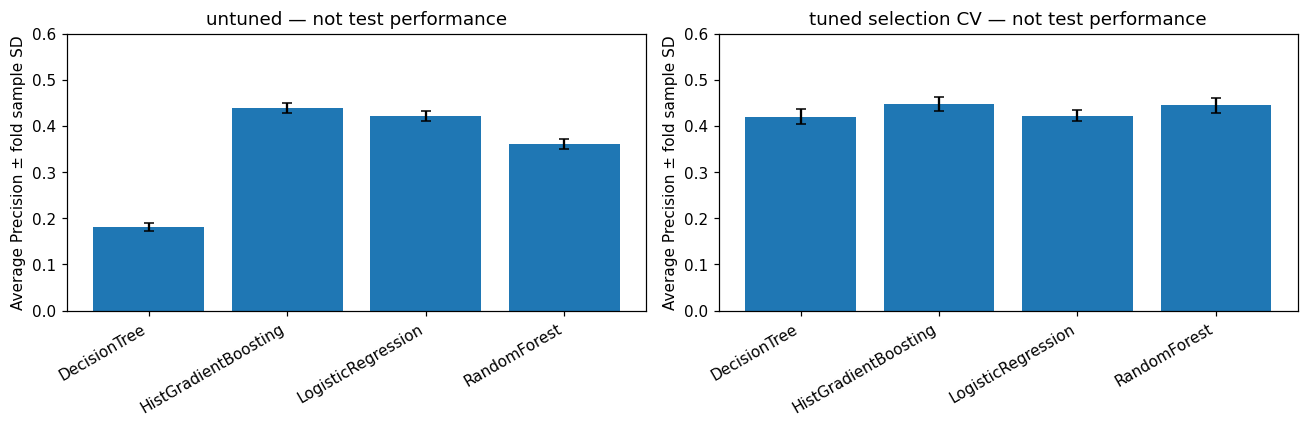

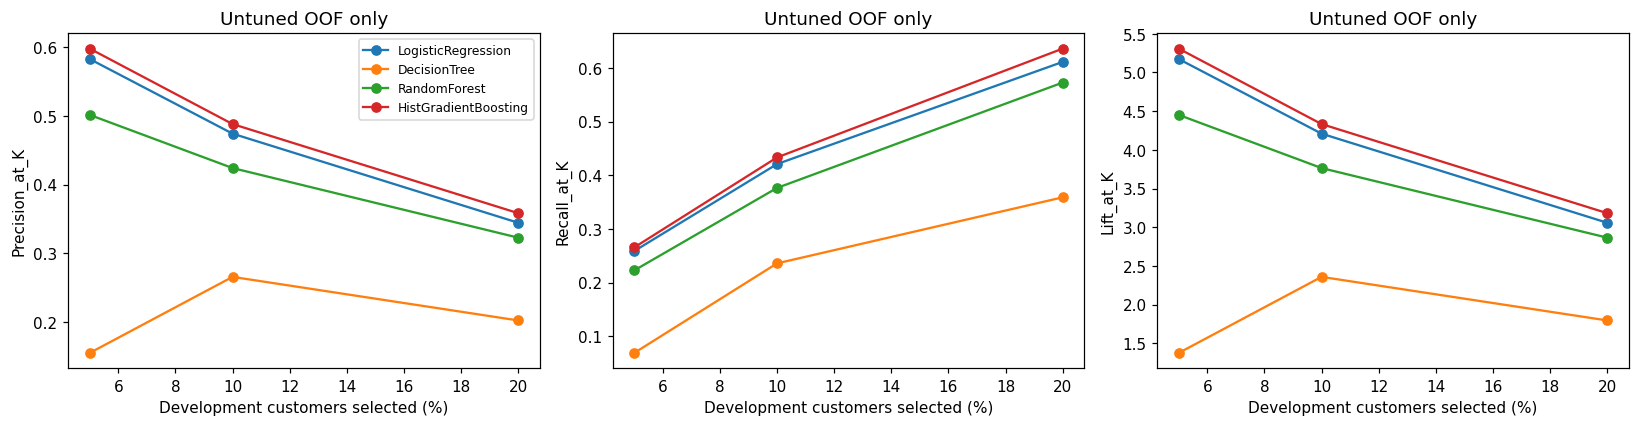

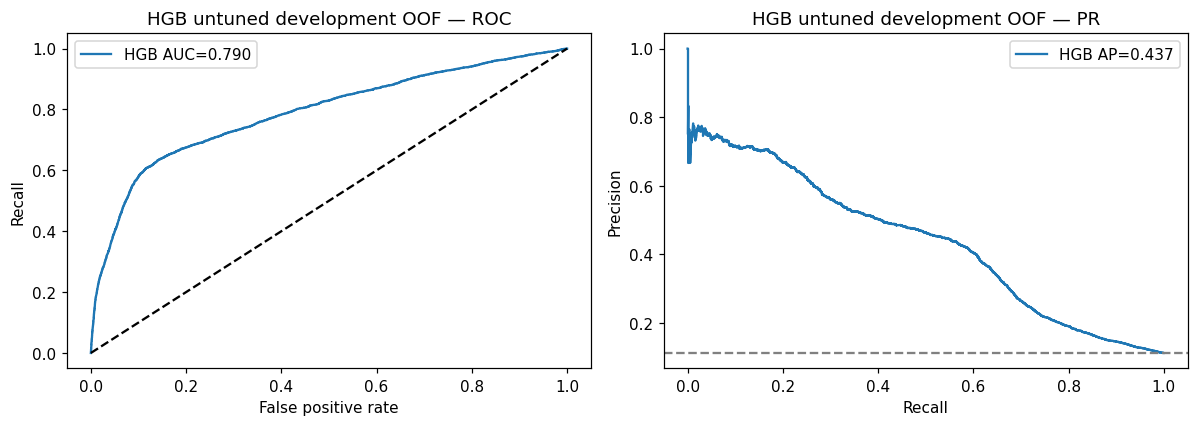

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for stage in ['untuned','tuned selection CV']:
    m=means.loc[stage];sd=sds.loc[stage];loc=np.arange(len(m))
    ax=axes[0 if stage=='untuned' else 1]
    ax.bar(loc,m.AP,yerr=sd.AP,capsize=3);ax.set_xticks(loc,m.index,rotation=30,ha='right')
    ax.set(ylabel='Average Precision ± fold sample SD',title=stage+' — not test performance',ylim=(0,.6))
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['Precision_at_K','Recall_at_K','Lift_at_K']):
    for name in business_comparison.model.unique():
        b=business_comparison[business_comparison.model.eq(name)];ax.plot(b.target_fraction*100,b[metric],marker='o',label=name)
    ax.set(xlabel='Development customers selected (%)',ylabel=metric,title='Untuned OOF only')
axes[0].legend(fontsize=8);plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4));fpr,tpr,_=roc_curve(y,oof);pr,re,_=precision_recall_curve(y,oof)
axes[0].plot(fpr,tpr,label=f'HGB AUC={roc_auc_score(y,oof):.3f}');axes[0].plot([0,1],[0,1],'k--')
axes[1].plot(re,pr,label=f'HGB AP={average_precision_score(y,oof):.3f}');axes[1].axhline(y.mean(),ls='--',color='gray')
axes[0].set(xlabel='False positive rate',ylabel='Recall',title='HGB untuned development OOF — ROC')
axes[1].set(xlabel='Recall',ylabel='Precision',title='HGB untuned development OOF — PR')
for ax in axes:ax.legend()
plt.tight_layout();plt.show()



## 7. Validation, factual summary and Phase 5A discussion

Audit all 86 fresh fits and 85 development-validation predictions, including post-search-refit separation, training-only categories, unchanged numeric/recency output, finite values, fixed seeds/iteration budgets and warning logs. Preserve all earlier file bytes and saved indices. Recheck existing preprocessing tests separately without running old-model grids.

All 15 features remain Provisional: age, job, marital, education, default, housing, loan, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed, recency_available, recency_days. Preprocessing leakage is controlled, but timestamps/customer histories are absent: pre-campaign snapshots, history cutoff/pdays reference date, economic publication/revision vintage and label window remain unresolved. Random stratified folds cannot eliminate repeated-customer or temporal overlap. Prior whole-data EDA exposure must be disclosed.

Use observed AP/ROC/Top-K variability and compute to recommend candidates, not automatically the most complex model. Approve a candidate shortlist, selection-bias-aware validation budget, timing assumptions/metadata and business objectives before Phase 5A. No claim of full leakage freedom, causal lift or independent generalization. No new phase, commit or push.


In [7]:
for name,digest in input_hashes.items():assert sha(PROJECT_DIR/name)==digest,name+' changed'
pd.testing.assert_frame_equal(dev,snapshot,check_exact=True)
assert np.isfinite(all_folds[METRICS].to_numpy(dtype=float)).all()
assert np.isfinite(business_comparison.select_dtypes('number').to_numpy()).all()
print('All audits passed: 86 fresh fits, 85 development-only validation calls; all prior files unchanged.')

def mdtable(frame,index=False):
    t=frame.reset_index() if index else frame.copy()
    def fmt(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,t.columns))+' |','| '+' | '.join(['---']*len(t.columns))+' |']+['| '+' | '.join(fmt(v) for v in row)+' |' for row in t.itertuples(index=False,name=None)])
hu=means.loc[('untuned','HistGradientBoosting')];ht=means.loc[('tuned selection CV','HistGradientBoosting')]
rf=means.loc[('tuned selection CV','RandomForest')]
ranked=means.loc['tuned selection CV'].sort_values('AP',ascending=False);leader=ranked.index[0]
base_rank=means.loc['untuned'].sort_values('AP',ascending=False)
warntext=mdtable(pd.DataFrame(WARNINGS)) if WARNINGS else 'None recorded across all 86 HGB fits.'
fit_summary=pd.DataFrame(FIT_AUDIT).groupby(['phase','rows']).size().rename('fit_count').reset_index()
cm=confusion_matrix(y,(oof>=.5).astype(int),labels=[0,1]);tn,fp,fn,tp=map(int,cm.ravel())
elapsed=time.perf_counter()-start_all
summary=f"""# Phase 4B — HistGradientBoosting development and fair comparison

## Scope and preservation

Added only HistGradientBoostingClassifier (HGB), with the approved 15 Provisional predictors and the same 32,940-row development assignment. Held-out 8,236-row features/labels were not parsed, fitted, evaluated, plotted or used for selection. No new train-test split, old-model grids or nested CV were run. Raw/cleaned CSVs, split JSON, preprocessing.py and earlier Phase 3/4 artifacts remain unchanged.

Reviewed README, project DOCX, Phase 2C summary, Phase 3 summary, Phase 4 notebook/summary, cleaned schema/data and saved split. Exact cleaned SHA-256 `{input_hashes['02_cleaned_dataset.csv']}` verified before indices; this binds both content and ordering. Only development CSV rows were parsed, then reordered to saved development positions. Five identical StratifiedKFold(5,shuffle=True,random_state=42) pairs were regenerated from that same ordered development set, and Phase 4 notebook code was checked for the identical recipe/factory. Each fold trains on 26,352 rows and validates on 6,588; coverage/disjointness/reproducibility passed. Validation-position checksum `{fold_hash}`.

Versions: sklearn {sklearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}. Standard Colab packages with sklearn >=1.2 are sufficient. Notebook executed locally; hosted Colab is not claimed. threadpoolctl limits OpenMP/BLAS to one thread during fit/prediction to avoid uncontrolled CPU cost; GridSearchCV n_jobs=1.

## Compatibility before training and minimal implementation

No additional model configuration in preprocessing.py is necessary. `make_preprocessor('decision_tree')` is exactly the existing approved unscaled numeric/one-hot setup also used for RF. HGB consumes its dense finite numeric output. Explicit `categorical_features=None` prevents native category inference: each one-hot level is a separate numeric 0/1 feature, not a categorical column index or integer level. No new encoding, native-category mode or LR-preprocessing change.

A stateless experiment-only FiniteNumericCheck step checks array/dtype/finiteness, numeric one-hot and availability bits, recency bounds and zero unavailable placeholders after approved preprocessing and **before classifier fitting on every fold**. It returns values unchanged, with no learned scaling/encoding. Raw development numeric domains were validated first. sklearn cloneability of the complete pipeline was checked before fitting; GridSearchCV subsequently cloned it successfully 81 times. Fitted HGB categorical masks and disabled early-stopping state were asserted on every fit.

## Untuned baseline configuration and results

learning_rate=0.1, max_iter=100, max_leaf_nodes=31, l2_regularization=0.0, early_stopping=False, random_state=42, class_weight=None, categorical_features=None. Other sklearn defaults retained (including min_samples_leaf=20 and log_loss). Classification rule is probability >=0.5, identical to Phase 4, including tie convention. Precision/recall/F1 use zero_division=0. Positive probabilities supply ROC-AUC/AP. AP means Average Precision, not trapezoidal PR area.

{mdtable(untuned)}

Untuned mean: accuracy {hu.Accuracy:.6f}, precision {hu.Precision:.6f}, recall {hu.Recall:.6f}, F1 {hu.F1:.6f}, ROC-AUC {hu.ROC_AUC:.6f}, AP {hu.AP:.6f}. All means/sample SDs are in the four-model table below. Pooled OOF confusion matrix (actual rows no/yes, predicted columns no/yes): [[{tn},{fp}],[{fn},{tp}]].

## Prespecified 16-configuration grid and cost

learning_rate=[0.05,0.1], max_iter=[100,200], max_leaf_nodes=[15,31], l2_regularization=[0.0,1.0]. learning_rate controls shrinkage per stage; max_iter fixes boosting stages; max_leaf_nodes controls interaction/partition complexity; l2_regularization penalizes leaf values, potentially stabilizing small/noisy regions. No expansion/reduction based on validation or held-out results. All candidates keep early_stopping=False, seed=42, class_weight=None and categorical_features=None.

GridSearchCV uses the same five folds, joint six-metric probability scorer, refit='AP', n_jobs=1, error_score='raise', return_train_score=False. 16 candidates × 5 folds = 80 candidate-fold fits, plus one winning development refit; five untuned folds bring the total to **86 HGB fits**. The refit occurs only after selection, not before CV; its training predictions are never used for targeting or reported performance, and no fitted artifact is saved. With early stopping disabled every fit ran its specified 100/200 iterations; no internal validation partition was created.

All candidates, including AP/ROC-AUC sample SD and mean fit/scoring time:

{mdtable(candidates[['parameters','rank_AP','AP_mean','AP_SD','ROC_AUC_mean','ROC_AUC_SD','mean_fit_seconds','mean_score_seconds']])}

Best selected parameters: `{json.dumps(search.best_params_,sort_keys=True)}`.

Selected configuration's five fold scores:

{mdtable(selected)}

These are tuning-reused model-selection estimates, potentially optimistic, **not independent generalization estimates**. Sample SD uses ddof=1 and is recomputed from five split values (GridSearchCV's stored std uses ddof=0). Folds share training data; neither those SDs nor small mean differences establish statistical significance.

## Four-model comparison — previous results imported, not rerun

{mdtable(comparison,index=True)}

Old LR/DT/RF values are reconstructed from Phase 4's six-decimal published fold rows. Thus comparisons carry rounding error of approximately 1e-6; old experiments and grids were not rerun or overwritten. HGB values come from this execution. Untuned AP ordering: {', '.join(base_rank.index)}. Tuned selection AP ordering: {', '.join(ranked.index)}.

HGB selected AP={ht.AP:.6f} versus RF={rf.AP:.6f}, difference {ht.AP-rf.AP:+.6f}; ROC-AUC={ht.ROC_AUC:.6f} versus RF={rf.ROC_AUC:.6f}, difference {ht.ROC_AUC-rf.ROC_AUC:+.6f}. Evaluate these descriptive differences alongside sample SD, compute and selection bias; no paired significance test or nested estimate was run. Small gains alone do not prove practically meaningful improvement, and greater model complexity is not automatically preferable. The AP advantage is small relative to observed fold-to-fold spread (HGB sample SD {sds.loc[('tuned selection CV','HistGradientBoosting'),'AP']:.6f}; RF {sds.loc[('tuned selection CV','RandomForest'),'AP']:.6f}). That supports further comparison rather than a conclusion that HGB should replace RF; it is not a paired significance test.

Measured cost, including unchanged imported Phase 4 timing for context:

{mdtable(cost)}

HGB experiment elapsed {elapsed:.2f} seconds including scoring/audits/plots; untuned CV {untuned_seconds:.2f}s, grid+refit {search_seconds:.2f}s. Candidate fit times exclude scoring/refit overhead. Imported timings are historical runtime measurements, not a controlled hardware benchmark or guaranteed Colab runtime; HGB thread counts were explicitly limited. The grid was kept intact. No old-model compute is included as a new run.

## Development-only pooled OOF targeting — untuned models only

K=ceil(fraction*N); rank descending probability, break ties by saved cleaned-row position, never outcome labels. Exactly K records selected. Precision@K=captured/K; Recall@K=captured/{int(y.sum())}; Lift@K=Precision@K/{float(y.mean()):.6f}. Development prevalence={float(y.mean())*100:.4f}%. No known costs, subscription values or campaign capacity are assumed.

{mdtable(business_comparison)}

At top 10%, untuned HGB captures {int(new_business.loc[new_business.target_fraction.eq(.1),'captured_subscribers'].iloc[0]):,} subscribers versus LR {int(old_business.loc[old_business.model.eq('LogisticRegression') & old_business.target_fraction.eq(.1),'captured_subscribers'].iloc[0]):,} at the same contact volume. Compare precision/recall/lift and costs in the table above: this is descriptive historical targeting gain, not causal or independent-test evidence.

Contact volume and captured subscriber counts are historical validation observations, not actual assigned outreach or evidence outreach caused subscription. Smaller fractions may offer greater concentration, broader fractions more capture; inspect the observed trade-off. Tie rules can materially affect coarse tree scores. Pooled OOF combines five model probability scales and overlapping training sets, so also inspect fold-local rankings rather than treating pooled ranking as a single deployable model.

HGB fold-local targeting details (contact/capture counts included):

{mdtable(fold_business)}

Four-model fold-local mean ± sample SD comparison (old models imported):

{mdtable(fold_comparison)}

No tuned HGB Top-K predictions were produced. Comparing selected-tuned HGB targeting against untuned LR/RF would mix experiments and selection bias. Future less-biased tuned targeting requires outer-fold predictions with tuning confined to each outer training partition. A five-outer/five-inner HGB-only experiment with this grid would add 5*(80 inner fits+1 refit)=405 fits. No nested CV was started; it would still not remove timing/client overlap limitations.

## Technical validation and warning log

{mdtable(fit_summary)}

All 86 fits started with fresh approved preprocessors. Training partitions match the fixed training folds except one explicit post-search full-development refit. OHE vocabularies equal training-only observed categories; no global encoded matrix or caching/reuse of fitted preprocessing. Numeric indicators verified before HGB fit; fitted categorical mask confirms no native categorical interpretation. Every fit uses early_stopping=False, correct iteration count, no class weights and seed=42. All 85 probability calls used exact development validation folds; complete feature names/category snapshots stayed unchanged and all transformed/probability/metric values were finite. Unscaled numeric/recency/availability outputs exactly matched validation input; unavailable recency remains 0 and no 999 sentinel is reintroduced.

The LR factory and custom ConditionalRecencyScaler are not called or modified for these experiments; their approved behavior is preserved byte-for-byte. All four existing preprocessing unit tests passed when rerun as a regression check; no LR experiment was run. Input hashes and in-memory development equality passed after execution; saved split and earlier artifacts are unchanged. No held-out matrix was constructed or predicted.

Warnings/errors:

{warntext}

## Business implications and Phase 5A recommendation

Current leading AP-selected family is **{leader}**. Consider **HistGradientBoosting and Random Forest** for a selection-bias-aware Phase 5A comparison, with Logistic Regression retained as a simpler reference and strong untuned targeting comparator. Use actual tables above rather than automatically declaring boosting superior. The selected HGB/RF scores are not independent test results; business value also needs capacity/cost/error trade-offs. No final model or threshold is selected here. No class-weighting/resampling/threshold experiment is authorized by this report.

All 15 predictors remain Provisional: {', '.join(FEATURES)}. Fold-specific preprocessing controls preprocessing leakage; historical-contact cutoff and recency reference dates, economic publication/revision vintage, campaign-start customer/status snapshots and target outcome/follow-up window remain unverified. No customer IDs or campaign dates means random stratified folds can overlap customers/economic periods; prior whole-dataset EDA also requires disclosure. No claim of full leakage freedom, causal outreach lift, unseen-customer or future-period generalization.

Team approval still needed: whether observed AP/ROC/Top-K differences and compute justify advancing HGB; candidate shortlist and nested-CV budget/estimand; campaign-start metadata/assumptions; correlated variables/rare-level policy for future work; and business capacity/error values before any threshold decisions. Keep the holdout untouched for a later approved final evaluation.

Deliverables: executed 05b_hist_gradient_boosting.ipynb and this 05b_hist_gradient_boosting_summary.md in the repository. No commit/push, nested CV or Phase 5A work; stop after Phase 4B.
"""
(PROJECT_DIR/'05b_hist_gradient_boosting_summary.md').write_text(summary)
print('Summary saved; stop after Phase 4B, pending approval.')


All audits passed: 86 fresh fits, 85 development-only validation calls; all prior files unchanged.
Summary saved; stop after Phase 4B, pending approval.
